# PUC-SP — Inteligência Artificial e Aprendizado de Máquina
## Mini Projeto de IA Não Supervisionada: Modelagem e Exploração de Algoritmos de Clusterização

---

### Integrantes da Dupla
* **Cesar Gritti** — GitHub: [@Ce-22](https://github.com/Ce-22) — E-mail: `cesargritti05@gmail.com`
* **Patrick Barreira** — GitHub: [@PatrickBarreira0](https://github.com/PatrickBarreira0) — E-mail: `patrick.barreira@cittamobi.com.br`

---

### 1. Contexto e Objetivos do Estudo
O presente projeto aborda o paradigma de **Aprendizado Não Supervisionado** (*Unsupervised Machine Learning*), cujo propósito central é identificar padrões latentes, estruturas intrínsecas e agrupamentos naturais em conjuntos de dados multivariados sem a necessidade de rótulos pré-existentes (*ground truth*).

Para garantir originalidade e relevância analítica, escolhemos no Kaggle o conjunto de dados **Customer Personality Analysis** (`marketing_campaign.csv`), composto por **2.240 registros** e **29 atributos** que caracterizam aspectos sociodemográficos, hábitos de consumo por categoria de produto, canais de aquisição e respostas a campanhas publicitárias.

Os objetivos centrais deste laboratório contemplam:
1. **Análise Exploratória de Dados (EDA)** e diagnóstico de valores nulos, distribuições assimétricas e correlações lineares;
2. **Engenharia de Atributos** e tratamento de inconsistências/outliers demográficos;
3. **Normalização e Redução de Dimensionalidade com PCA** (*Principal Component Analysis*);
4. **Experimentação Comparativa de Modelos de Clusterização**:
   * **K-Means** (Particionamento com critério de minimização de inércia);
   * **Affinity Propagation** (Agrupamento baseado em troca de mensagens e identificação de exemplares);
   * **Agrupamento Hierárquico Aglomerativo** (Critério de variância mínima de Ward e Dendrograma);
   * **DBSCAN** (Agrupamento baseado em densidade e identificação de ruído);
   * **Gaussian Mixture Models (GMM)** (Abordagem probabilística de densidades Gaussianas latentes);
5. **Avaliação Quantitativa** por meio dos coeficientes de **Silhouette**, índice de **Davies-Bouldin** e escore de **Calinski-Harabasz**;
6. **Interpretação de Negócio e Personas de Consumidores** para acionamento estratégico em marketing.


### 2. Fundamentação Teórica dos Métodos de Agrupamento

#### A. K-Means (Minimização de Variância Intra-Cluster - WCSS)
O algoritmo K-Means particiona $N$ observações em $K$ clusters disjuntos $C = \{C_1, C_2, \dots, C_K\}$, minimizando a soma dos quadrados das distâncias euclidianas dos pontos aos seus respectivos centróides $\mu_k$:
$$J(C) = \sum_{k=1}^K \sum_{x_i \in C_k} \| x_i - \mu_k \|^2$$

A determinação do $K$ ótimo utiliza o **Método do Cotovelo** (*Elbow Method*) e a análise do **Coeficiente de Silhouette**:
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
onde $a(i)$ é a distância média intra-cluster de $x_i$ e $b(i)$ é a distância média até o cluster vizinho mais próximo.

#### B. Affinity Propagation (Propagação de Afinidade por Mensagens)
Diferente do K-Means, o Affinity Propagation não exige a especificação prévia do número de clusters. Ele opera tratando todos os pontos como potenciais **exemplares** (*exemplars*) e transmitindo duas mensagens reais recursivamente:
1. **Responsabilidade** $r(i, k)$: Reflete o quão adequado o ponto $k$ é para servir de exemplar para o ponto $i$:
   $$r(i, k) \leftarrow s(i, k) - \max_{k' \neq k} \{ a(i, k') + s(i, k') \}$$
2. **Disponibilidade** $a(i, k)$: Reflete o quão apropriado é para o ponto $i$ escolher $k$ como seu exemplar:
   $$a(i, k) \leftarrow \min \left( 0, r(k, k) + \sum_{i' \notin \{i, k\}} \max(0, r(i', k)) \right)$$

O parâmetro de amortecimento (*damping factor* $\lambda \in [0.5, 1.0)$) evita oscilações numéricas, enquanto o *preference* dita a propensão dos pontos a se tornarem exemplares.

#### C. Agrupamento Hierárquico Aglomerativo (Critério de Ward)
Abordagem *bottom-up* em que cada amostra inicia em seu próprio cluster unitário e pares de clusters são sucessivamente fundidos minimizando o aumento da soma total de quadrados intra-cluster:
$$\Delta \text{ESS}_{A, B} = \frac{n_A n_B}{n_A + n_B} \| \mu_A - \mu_B \|^2$$

A estrutura hierárquica é sintetizada em um **Dendrograma**, viabilizando cortes a diferentes distâncias de ligação.


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    AffinityPropagation,
    AgglomerativeClustering,
    DBSCAN
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score
)

from lab_helpers import (
    load_and_preprocess_customer_data,
    compute_clustering_metrics,
    evaluate_kmeans_range,
    summarize_cluster_profiles
)

# Configuração de estilo visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Ambiente configurado com sucesso. Dependências carregadas.")


Ambiente configurado com sucesso. Dependências carregadas.


### 3. Carregamento do Dataset, Limpeza e Engenharia de Atributos

O dataset original possui atributos tabulares separados por `\t`. As seguintes etapas de tratamento são executadas:
* **Imputação de Renda (`Income`):** 24 registros nulos são imputados pela mediana estratificada por grau de instrução (`Education`);
* **Filtro de Inconsistências:** Remoção de anomalias com ano de nascimento anterior a 1920 e renda atípica superior a $600.000;
* **Engenharia de Atributos:** Criação das métricas agregadas `Age`, `Total_Spent`, `Total_Purchases`, `Children`, `Family_Size`, `Customer_Days` e `Total_Accepted_Cmp`;
* **Descarte de Colunas Redundantes:** Descarte de identificador `ID` e variáveis de custo constantes sem variância (`Z_CostContact`, `Z_Revenue`).


In [2]:
csv_path = 'data/customer_personality_analysis.csv'
df_raw, df, feature_cols, X_scaled, scaler, pca, X_pca = load_and_preprocess_customer_data(csv_path)

print(f"Dimensões originais do dataset: {df_raw.shape}")
print(f"Dimensões após limpeza e feature engineering: {df.shape}")
print(f"Número de atributos numéricos selecionados para clusterização: {len(feature_cols)}")
print(f"Atributos selecionados: {feature_cols}")
df[['Income', 'Age', 'Total_Spent', 'Total_Purchases', 'Children', 'Family_Size', 'Total_Accepted_Cmp']].head()


Dimensões originais do dataset: (2240, 29)
Dimensões após limpeza e feature engineering: (2236, 37)
Número de atributos numéricos selecionados para clusterização: 10
Atributos selecionados: ['Income', 'Age', 'Total_Spent', 'Total_Purchases', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Children', 'Customer_Days', 'Total_Accepted_Cmp']


,Income,Age,Total_Spent,Total_Purchases,Children,Family_Size,Total_Accepted_Cmp
0,58138.0,69,1617,25,0,1,1
1,46344.0,72,27,6,2,3,0
2,71613.0,61,776,21,0,2,0
3,26646.0,42,53,8,1,3,0
4,58293.0,45,422,19,1,3,0


### 4. Análise Exploratória de Dados (EDA)
Examinamos o comportamento distribucional da renda anual, do volume total de gastos, da repartição de compras entre categorias de produto (vinhos, carnes, etc.) e a matriz de correlação de Pearson.


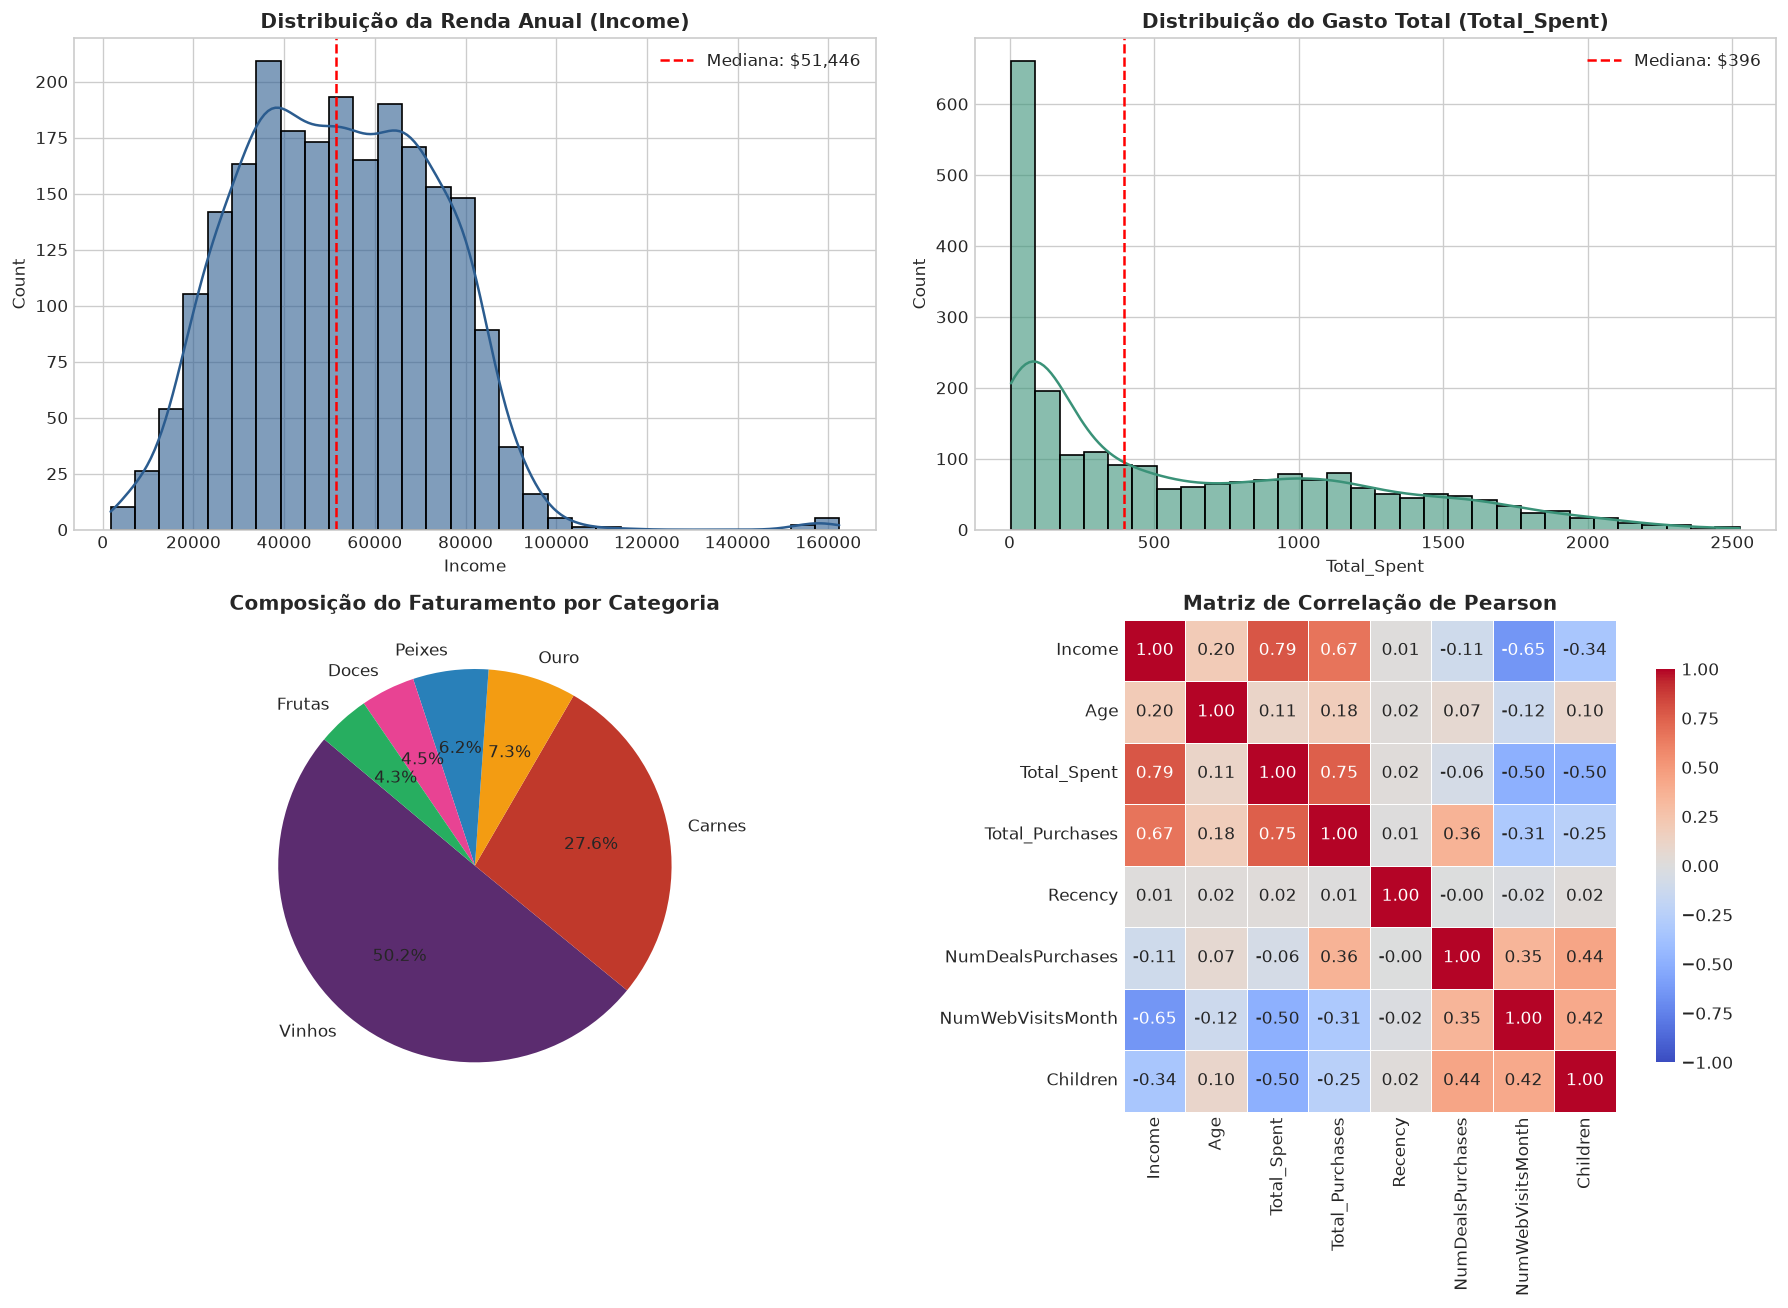

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(15, 11), dpi=120)

# 1. Distribuição de Renda
sns.histplot(df['Income'], kde=True, ax=axs[0, 0], color='#2b5c8f', bins=30, alpha=0.6)
axs[0, 0].set_title('Distribuição da Renda Anual (Income)', fontsize=12, fontweight='bold')
axs[0, 0].axvline(df['Income'].median(), color='red', linestyle='--', label=f'Mediana: ${df["Income"].median():,.0f}')
axs[0, 0].legend()

# 2. Distribuição de Gastos
sns.histplot(df['Total_Spent'], kde=True, ax=axs[0, 1], color='#3a9278', bins=30, alpha=0.6)
axs[0, 1].set_title('Distribuição do Gasto Total (Total_Spent)', fontsize=12, fontweight='bold')
axs[0, 1].axvline(df['Total_Spent'].median(), color='red', linestyle='--', label=f'Mediana: ${df["Total_Spent"].median():,.0f}')
axs[0, 1].legend()

# 3. Composição de Vendas por Categoria
spending_cols = ['MntWines', 'MntMeatProducts', 'MntGoldProds', 'MntFishProducts', 'MntSweetProducts', 'MntFruits']
spending_labels = ['Vinhos', 'Carnes', 'Ouro', 'Peixes', 'Doces', 'Frutas']
axs[1, 0].pie(df[spending_cols].sum(), labels=spending_labels, autopct='%1.1f%%', startangle=140,
              colors=['#5b2c6f', '#c0392b', '#f39c12', '#2980b9', '#e84393', '#27ae60'])
axs[1, 0].set_title('Composição do Faturamento por Categoria', fontsize=12, fontweight='bold')

# 4. Heatmap de Correlação
corr_cols = ['Income', 'Age', 'Total_Spent', 'Total_Purchases', 'Recency', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Children']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=axs[1, 1], cbar_kws={'shrink': 0.8})
axs[1, 1].set_title('Matriz de Correlação de Pearson', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 5. Redução de Dimensionalidade com PCA

A aplicação do PCA reduz o espaço vetorial de 10 atributos padronizados para componentes ortogonais descorrelacionados, facilitando a visualização e mitigando a "maldição da dimensionalidade" (*curse of dimensionality*) que afeta cálculos de distância euclidiana em espaços de alta dimensão.


Variância explicada por cada componente:
  PC1: 33.65% (Acumulado: 33.65%)
  PC2: 17.48% (Acumulado: 51.13%)
  PC3: 12.10% (Acumulado: 63.23%)
  PC4: 10.22% (Acumulado: 73.45%)
  PC5: 8.29% (Acumulado: 81.74%)
  PC6: 7.68% (Acumulado: 89.42%)
  PC7: 4.76% (Acumulado: 94.17%)
  PC8: 3.02% (Acumulado: 97.19%)
  PC9: 1.56% (Acumulado: 98.75%)
  PC10: 1.25% (Acumulado: 100.00%)


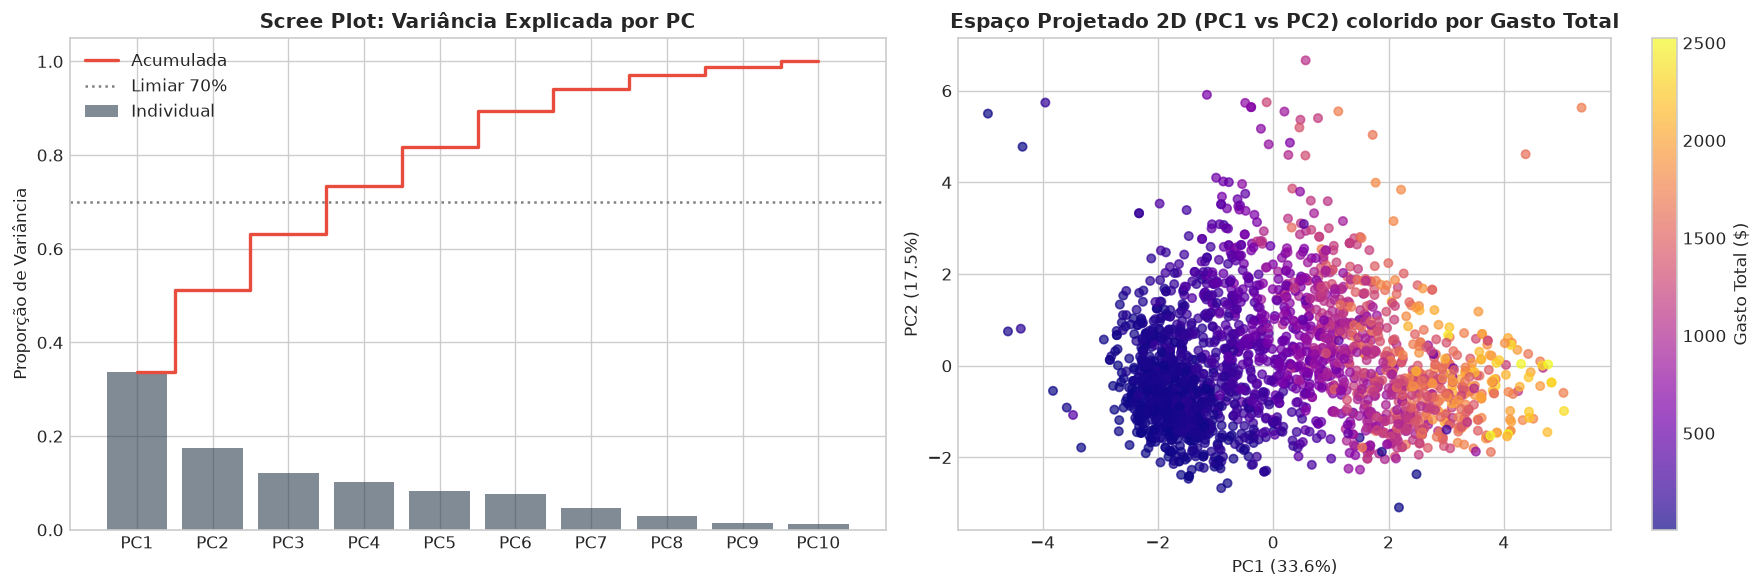

In [4]:
pca_full = PCA(n_components=len(feature_cols), random_state=42).fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_
cum_var_exp = np.cumsum(var_exp)

print("Variância explicada por cada componente:")
for i, (v, c) in enumerate(zip(var_exp, cum_var_exp)):
    print(f"  PC{i+1}: {v*100:.2f}% (Acumulado: {c*100:.2f}%)")

fig, axs = plt.subplots(1, 2, figsize=(15, 5), dpi=120)

pcs = [f'PC{i+1}' for i in range(len(var_exp))]
axs[0].bar(pcs, var_exp, alpha=0.6, color='#2c3e50', label='Individual')
axs[0].step(pcs, cum_var_exp, where='mid', color='#e74c3c', linewidth=2, label='Acumulada')
axs[0].axhline(y=0.70, color='gray', linestyle=':', label='Limiar 70%')
axs[0].set_title('Scree Plot: Variância Explicada por PC', fontsize=12, fontweight='bold')
axs[0].set_ylabel('Proporção de Variância')
axs[0].legend()

sc = axs[1].scatter(X_pca[:, 0], X_pca[:, 1], c=df['Total_Spent'], cmap='plasma', alpha=0.7, s=25)
cbar = plt.colorbar(sc, ax=axs[1])
cbar.set_label('Gasto Total ($)')
axs[1].set_title('Espaço Projetado 2D (PC1 vs PC2) colorido por Gasto Total', fontsize=12, fontweight='bold')
axs[1].set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
axs[1].set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')

plt.tight_layout()
plt.show()


### 6. Modelo 1: K-Means Clustering

Avaliamos valores de $k \in [2, 10]$ com o algoritmo K-Means ($n\_init=10$). Monitoramos a inércia (WCSS) e o Coeficiente de Silhouette médio para determinar a partição ótima.


In [5]:
metrics_kmeans = evaluate_kmeans_range(X_pca, k_min=2, k_max=10, random_state=42)
metrics_kmeans


,k,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,8413.166216,0.377143,1.103142,1520.005303
1,3,6154.443519,0.360479,1.068605,1448.226855
2,4,5199.517802,0.308413,1.102585,1278.934177
3,5,4378.070900,0.289539,1.128743,1243.319318
4,6,3851.950884,0.293059,1.151634,1190.918266
5,7,3496.072597,0.290842,1.051528,1130.811566
6,8,3200.341413,0.283105,1.044982,1087.735966
7,9,2965.106451,0.270008,1.077517,1048.934001
8,10,2787.573098,0.267894,1.094676,1007.042182


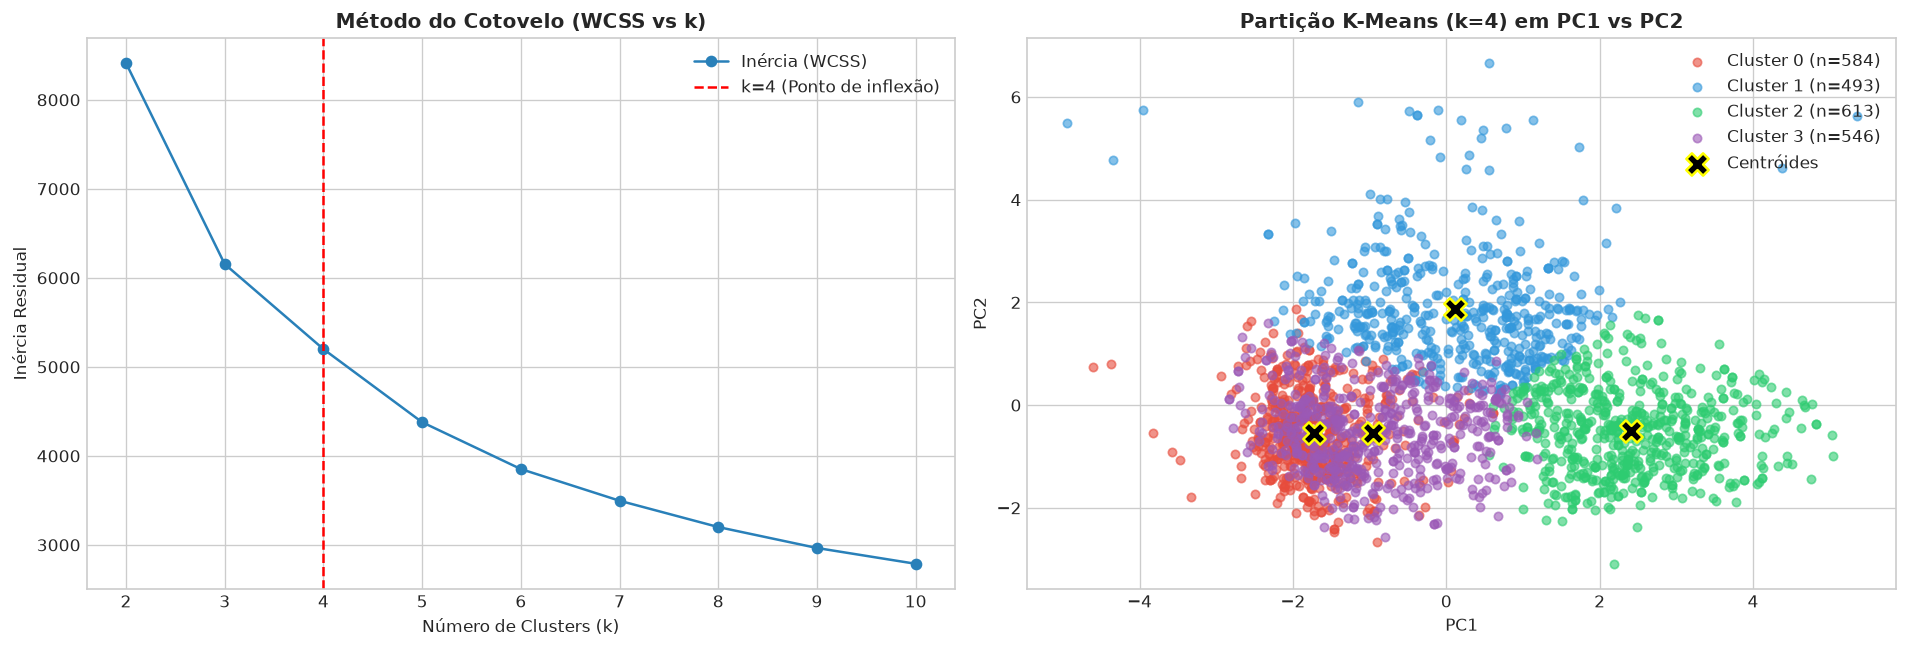

In [6]:
km_opt = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_pca)
labels_km = km_opt.labels_
centroids_km = km_opt.cluster_centers_

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

# Curvas de Elbow e Silhouette
axs[0].plot(metrics_kmeans['k'], metrics_kmeans['Inertia'], marker='o', color='#2980b9', label='Inércia (WCSS)')
axs[0].set_title('Método do Cotovelo (WCSS vs k)', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Número de Clusters (k)')
axs[0].set_ylabel('Inércia Residual')
axs[0].axvline(x=4, color='red', linestyle='--', label='k=4 (Ponto de inflexão)')
axs[0].legend()

# Scatter 2D com centróides
cluster_colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
for i in range(4):
    mask = labels_km == i
    axs[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=25, color=cluster_colors[i], alpha=0.6, label=f'Cluster {i} (n={np.sum(mask)})')
axs[1].scatter(centroids_km[:, 0], centroids_km[:, 1], marker='X', s=180, color='black', edgecolor='yellow', linewidth=1.5, label='Centróides')
axs[1].set_title('Partição K-Means (k=4) em PC1 vs PC2', fontsize=12, fontweight='bold')
axs[1].set_xlabel('PC1')
axs[1].set_ylabel('PC2')
axs[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


### 7. Modelo 2: Affinity Propagation

O Affinity Propagation não assume formatos hiper-esféricos e identifica **exemplares** representativos por meio de mensagens bidirecionais. Avaliamos a sensibilidade do número de clusters frente a diferentes valores de *preference* e fixamos amortecimento em $\lambda = 0.85$.


Preference adotado (quantil 5%): -5.784
Número de clusters/exemplares encontrados: 87
Silhouette Score do Affinity Propagation: 0.2488


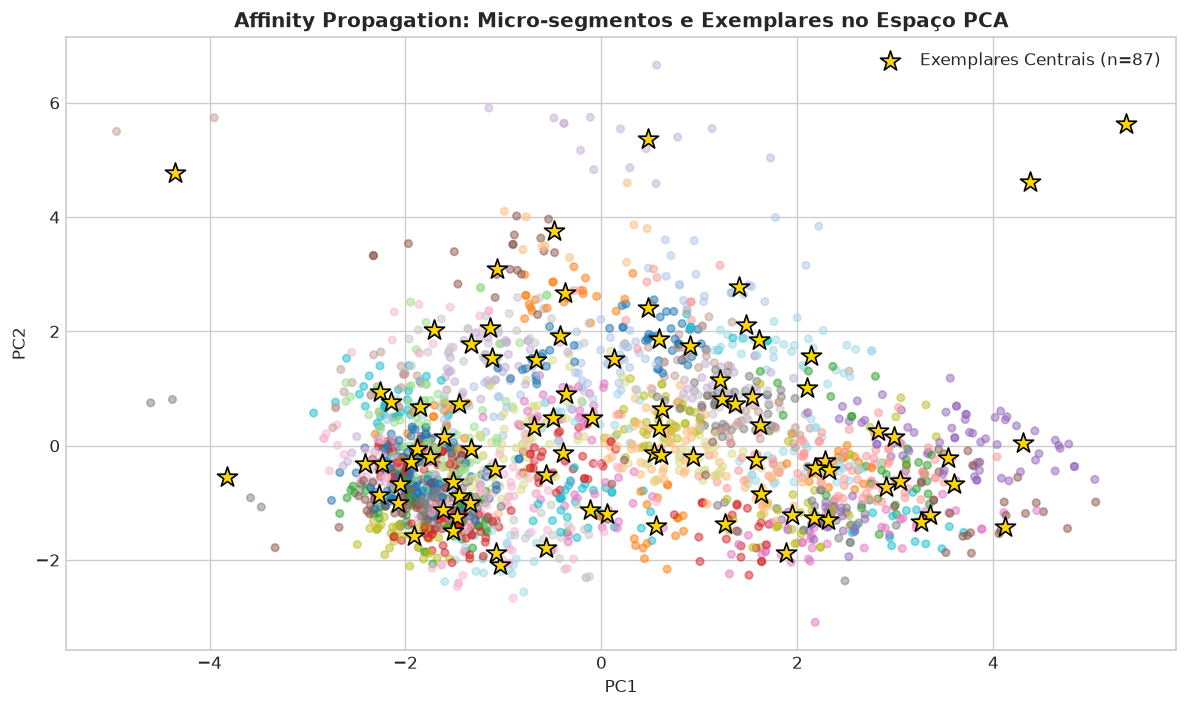

In [7]:
# Cálculo de matriz de similaridade euclidiana negativa
similarities = -np.linalg.norm(X_pca[:, None] - X_pca[None, :], axis=2)
pref_chosen = np.quantile(similarities, 0.05)

af_model = AffinityPropagation(damping=0.85, preference=pref_chosen, random_state=42, max_iter=300).fit(X_pca)
labels_af = af_model.labels_
exemplars = af_model.cluster_centers_indices_

print(f"Preference adotado (quantil 5%): {pref_chosen:.3f}")
print(f"Número de clusters/exemplares encontrados: {len(exemplars)}")
print(f"Silhouette Score do Affinity Propagation: {silhouette_score(X_pca, labels_af):.4f}")

plt.figure(figsize=(10, 6), dpi=120)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_af, cmap='tab20', s=20, alpha=0.5)
plt.scatter(X_pca[exemplars, 0], X_pca[exemplars, 1], marker='*', s=160, color='gold', edgecolor='black', label=f'Exemplares Centrais (n={len(exemplars)})')
plt.title('Affinity Propagation: Micro-segmentos e Exemplares no Espaço PCA', fontsize=12, fontweight='bold')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()


### 8. Modelo 3: Agrupamento Hierárquico Aglomerativo e Dendrograma

Utilizamos a ligação de Ward para construir a árvore de fusões hierárquicas e realizamos o corte em $k=4$ para comparação direta com o K-Means.


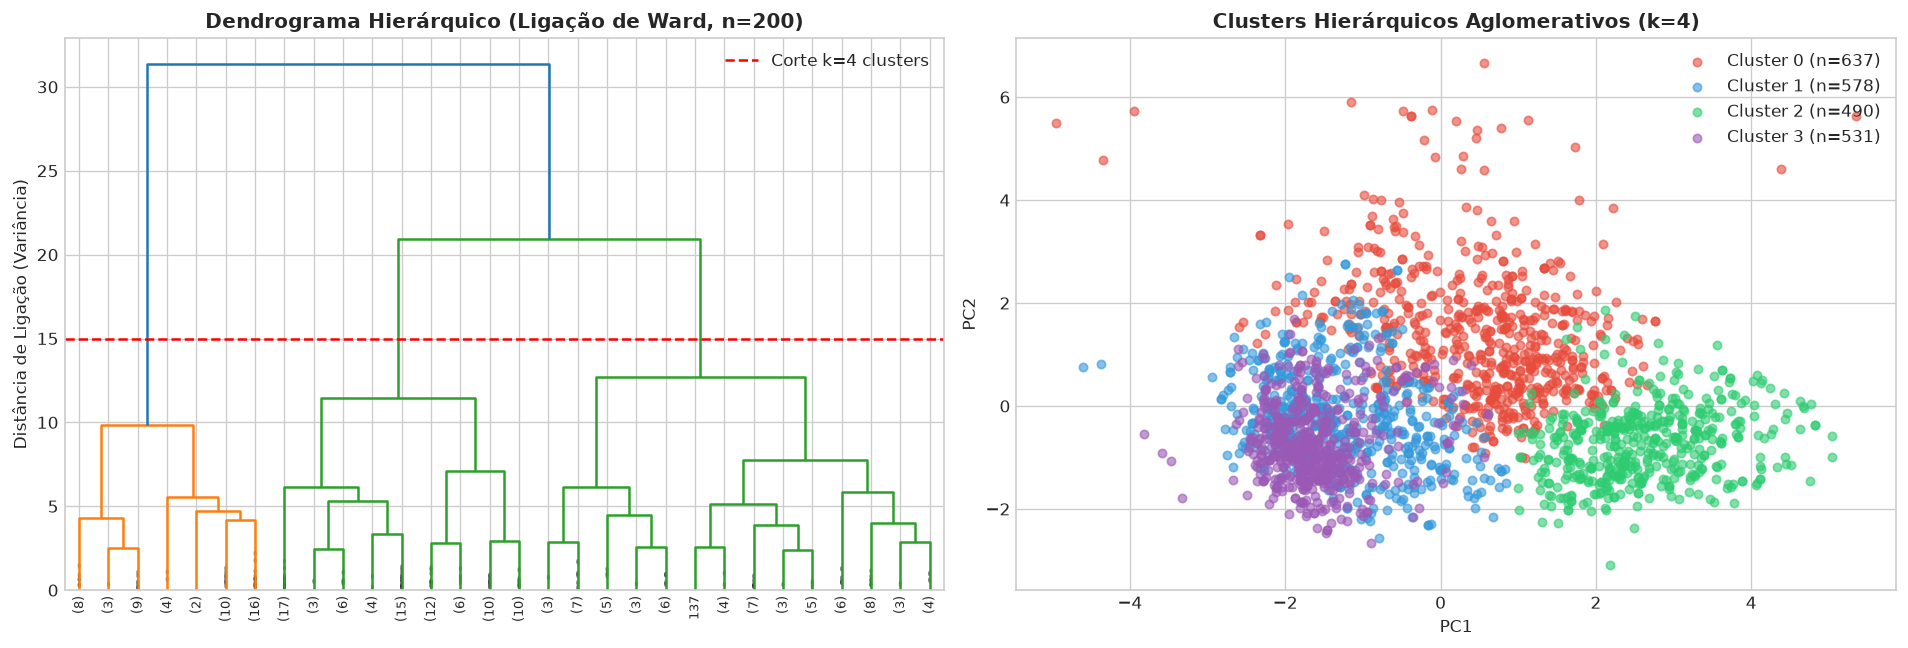

In [8]:
# Amostragem para geração visual do Dendrograma
np.random.seed(42)
idx_sample = np.random.choice(len(X_pca), size=200, replace=False)
Z = linkage(X_pca[idx_sample], method='ward')

agg_model = AgglomerativeClustering(n_clusters=4, linkage='ward').fit(X_pca)
labels_agg = agg_model.labels_

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

dendrogram(Z, ax=axs[0], truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=8., show_contracted=True)
axs[0].axhline(y=15.0, color='red', linestyle='--', label='Corte k=4 clusters')
axs[0].set_title('Dendrograma Hierárquico (Ligação de Ward, n=200)', fontsize=12, fontweight='bold')
axs[0].set_ylabel('Distância de Ligação (Variância)')
axs[0].legend()

for i in range(4):
    mask = labels_agg == i
    axs[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=25, color=cluster_colors[i], alpha=0.6, label=f'Cluster {i} (n={np.sum(mask)})')
axs[1].set_title('Clusters Hierárquicos Aglomerativos (k=4)', fontsize=12, fontweight='bold')
axs[1].set_xlabel('PC1')
axs[1].set_ylabel('PC2')
axs[1].legend()

plt.tight_layout()
plt.show()


### 9. Modelos Complementares: DBSCAN e Gaussian Mixture Models (GMM)
Para uma comparação abrangente entre paradigmas, ajustamos:
* **DBSCAN:** Modelo baseado em densidade que isola amostras com baixa densidade local como ruído ($label = -1$);
* **Gaussian Mixture (GMM):** Modelo probabilístico baseado na combinação convexa de $k=4$ distribuições normais multivariadas com matriz de covariância irrestrita.


In [9]:
# DBSCAN
db_model = DBSCAN(eps=0.5, min_samples=20).fit(X_pca)
labels_db = db_model.labels_

# GMM
gmm_model = GaussianMixture(n_components=4, random_state=42).fit(X_pca)
labels_gmm = gmm_model.predict(X_pca)

print(f"DBSCAN: {len(set(labels_db)) - 1} clusters válidos, {np.sum(labels_db == -1)} amostras de ruído ({np.sum(labels_db == -1)/len(X_pca)*100:.1f}%)")
print(f"GMM: {len(set(labels_gmm))} clusters identificados com densidades Gaussianas")


DBSCAN: 5 clusters válidos, 1127 amostras de ruído (50.4%)
GMM: 4 clusters identificados com densidades Gaussianas


### 10. Comparativo Quantitativo dos Modelos

Avaliamos a qualidade das partições segundo três métricas estatísticas:
1. **Silhouette Score:** Coesão intra-cluster versus separação inter-cluster (maior = melhor, $\in [-1, 1]$);
2. **Davies-Bouldin Index:** Razão de similaridade entre clusters (menor = melhor, $\ge 0$);
3. **Calinski-Harabasz Index:** Razão da dispersão inter-cluster sobre a dispersão intra-cluster (maior = melhor).


In [10]:
models_list = [
    ('K-Means (k=4)', labels_km),
    ('Affinity Propagation (p=q5%)', labels_af),
    ('Hierárquico (Ward, k=4)', labels_agg),
    ('Gaussian Mixture (k=4)', labels_gmm),
    ('DBSCAN (eps=0.5, ms=20)', labels_db)
]

comparison_df = pd.DataFrame([compute_clustering_metrics(X_pca, lbls, name) for name, lbls in models_list])
comparison_df.sort_values(by='Silhouette', ascending=False)


,Modelo,N_Clusters,Ruído,Silhouette,Davies-Bouldin,Calinski-Harabasz
4,"DBSCAN (eps=0.5, ms=20)",5,1127,0.4321,0.7863,704.92
0,K-Means (k=4),4,0,0.3084,1.1026,1278.93
3,Gaussian Mixture (k=4),4,0,0.2855,1.2339,1096.27
2,"Hierárquico (Ward, k=4)",4,0,0.2617,1.2569,1115.57
1,Affinity Propagation (p=q5%),87,0,0.2488,1.0019,531.74


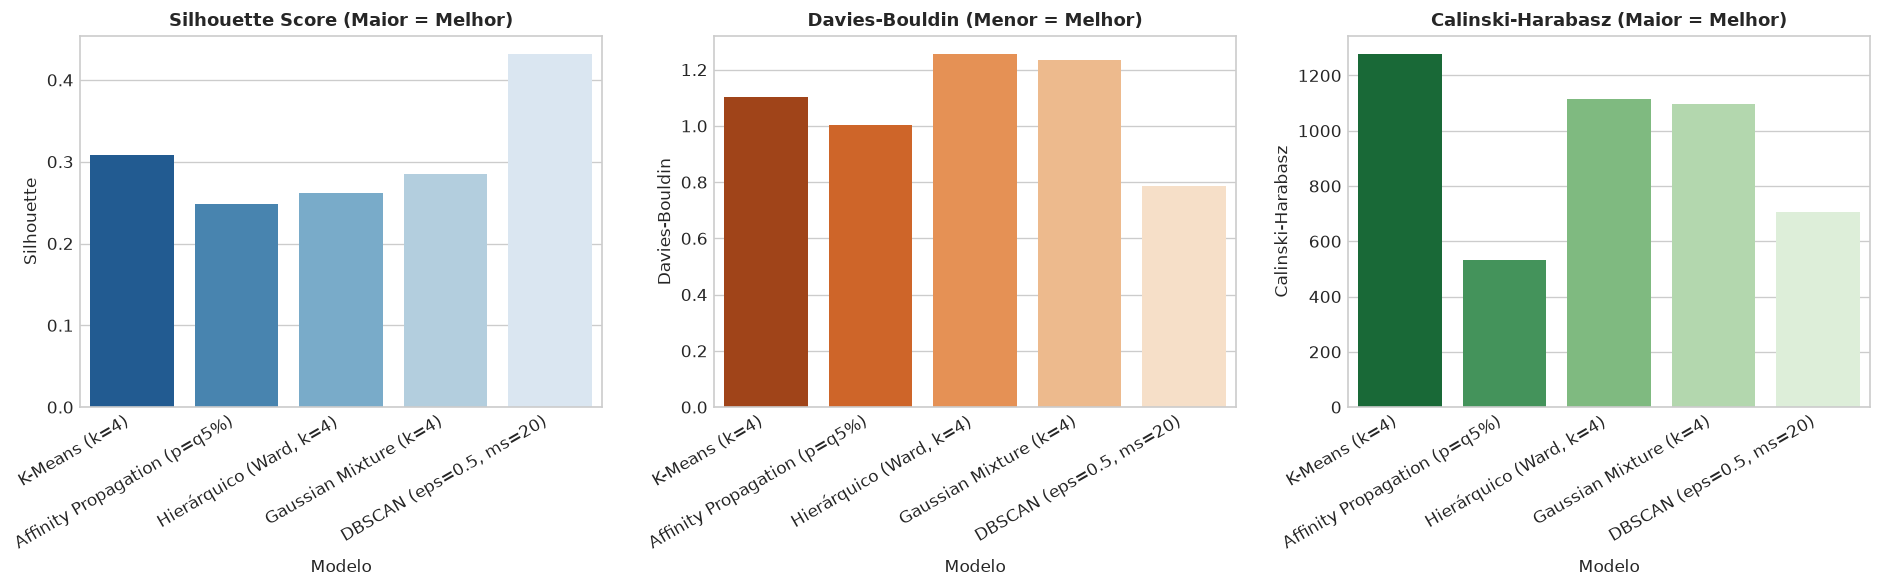

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5), dpi=120)

sns.barplot(data=comparison_df, x='Modelo', y='Silhouette', ax=axs[0], palette='Blues_r')
axs[0].set_title('Silhouette Score (Maior = Melhor)', fontsize=11, fontweight='bold')
axs[0].set_xticklabels(axs[0].get_xticklabels(), rotation=30, ha='right')

sns.barplot(data=comparison_df, x='Modelo', y='Davies-Bouldin', ax=axs[1], palette='Oranges_r')
axs[1].set_title('Davies-Bouldin (Menor = Melhor)', fontsize=11, fontweight='bold')
axs[1].set_xticklabels(axs[1].get_xticklabels(), rotation=30, ha='right')

sns.barplot(data=comparison_df, x='Modelo', y='Calinski-Harabasz', ax=axs[2], palette='Greens_r')
axs[2].set_title('Calinski-Harabasz (Maior = Melhor)', fontsize=11, fontweight='bold')
axs[2].set_xticklabels(axs[2].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()


### 11. Perfil dos Clusters e Construção de Personas de Negócio

Utilizando a partição de 4 clusters gerada pelo K-Means (modelo com melhor equilíbrio de interpretabilidade e Calinski-Harabasz), analisamos as características socioeconômicas e comportamentais de cada segmento para construir **Personas Acionáveis**.


In [12]:
cluster_personas = summarize_cluster_profiles(df, labels_km, 'Cluster_KMeans')
cluster_personas


,Total_Clientes,Share_%,Age,Income,Total_Spent,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumStorePurchases,NumCatalogPurchases,NumWebVisitsMonth,Recency,Children,Family_Size,Total_Accepted_Cmp
Cluster_KMeans,,,,,,,,,,,,,,,
0,584,26.1,48.79,29312.64,94.75,7.46,1.79,2.12,3.09,0.47,7.14,44.57,0.96,2.61,0.23
1,493,22.0,60.36,55490.24,751.51,21.80,4.79,6.30,7.41,3.29,6.53,49.43,1.34,2.98,0.39
2,613,27.4,58.00,76282.17,1337.75,20.41,1.16,5.23,8.34,5.69,2.81,48.91,0.23,1.85,1.02
3,546,24.4,62.04,45677.94,199.85,10.33,1.99,2.91,4.38,1.04,5.10,53.93,1.41,3.07,0.09


#### Síntese das 4 Personas Identificadas:

1. **Cluster 0 — Navegadores Digitais Econômicos (26,1% da base | Renda: $29k | Gasto: $95):**
   * *Perfil:* Clientes mais jovens (média 49 anos), baixa renda familiar, alto volume de visitas ao site (7,1 visitas/mês), porém ticket médio muito reduzido.
   * *Ação de Negócio:* Foco em produtos de entrada, frete grátis e promoções no canal web para conversão.

2. **Cluster 1 — Famílias Caçadoras de Ofertas (22,0% da base | Renda: $55k | Gasto: $752):**
   * *Perfil:* Presença de filhos (média 1,34), famílias com ~3 integrantes. Maior frequência total de compras (21,8 compras) e líder absoluto em compras com desconto (`NumDealsPurchases` = 4,79).
   * *Ação de Negócio:* Campanhas de cupons, ofertas de compras recorrentes no atacado/varejo físico e kits familiares.

3. **Cluster 2 — Elite VIP Connoisseurs (27,4% da base | Renda: $76k | Gasto: $1.338):**
   * *Perfil:* Maior poder aquisitivo ($76k anuais), ticket de gastos 14x superior ao Cluster 0, praticamente sem crianças em casa (0,23 filhos). Grandes consumidores de vinhos finos e carnes nobres. Alto uso de catálogo e alta adesão a campanhas (`Total_Accepted_Cmp` = 1,02).
   * *Ação de Negócio:* Programas de fidelidade VIP (*club de vinhos*), lançamentos exclusivos e atendimento personalizado via catálogo/e-mail direto.

4. **Cluster 3 — Adultos Tradicionais de Baixo Engajamento (24,4% da base | Renda: $46k | Gasto: $200):**
   * *Perfil:* Faixa etária mais madura (62 anos), presença de adolescentes em casa. Gasto moderado e menor taxa de resposta a campanhas publicitárias da base (0,09).
   * *Ação de Negócio:* Ofertas de utilidades do dia a dia em lojas físicas tradicionais e canais conservadores de comunicação.


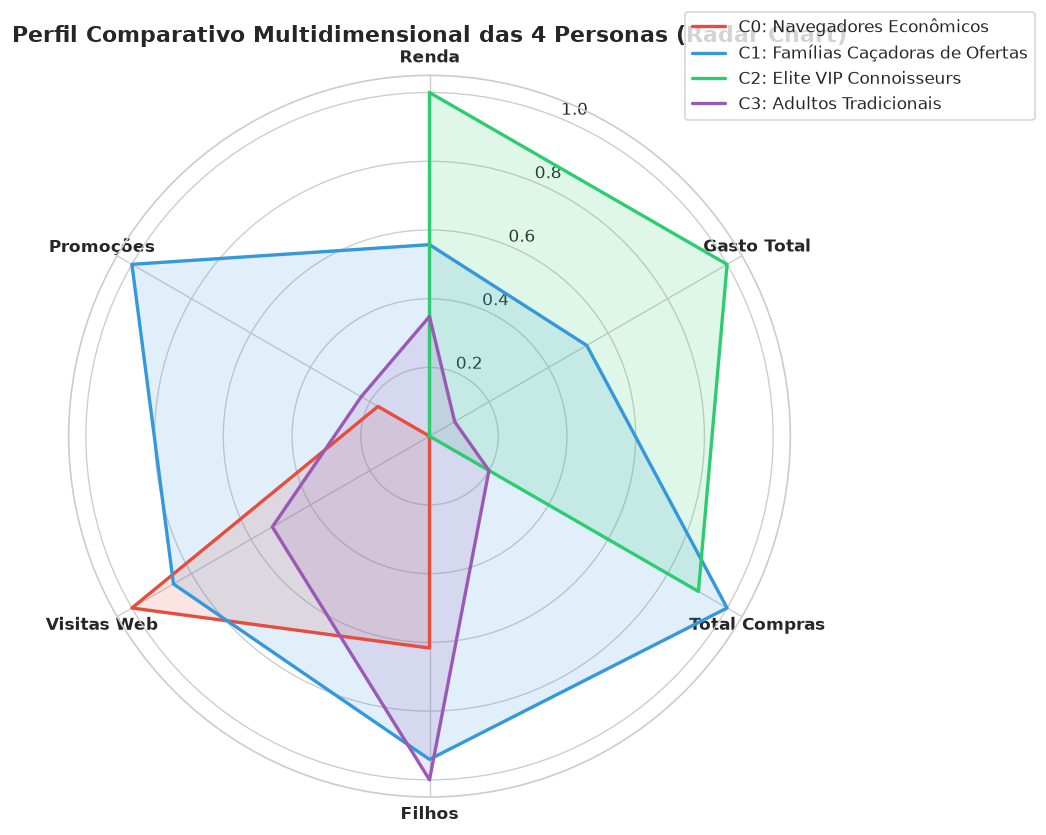

In [13]:
radar_cols = ['Income', 'Total_Spent', 'Total_Purchases', 'Children', 'NumWebVisitsMonth', 'NumDealsPurchases']
radar_names = ['Renda', 'Gasto Total', 'Total Compras', 'Filhos', 'Visitas Web', 'Promoções']

c_means = df.groupby(labels_km)[radar_cols].mean()
norm_means = (c_means - c_means.min()) / (c_means.max() - c_means.min() + 1e-5)

angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
angles += angles[:1]

fig = plt.figure(figsize=(9, 7), dpi=120)
ax = fig.add_subplot(111, polar=True)

persona_labels = [
    'C0: Navegadores Econômicos',
    'C1: Famílias Caçadoras de Ofertas',
    'C2: Elite VIP Connoisseurs',
    'C3: Adultos Tradicionais'
]

for i in range(4):
    vals = norm_means.iloc[i].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=cluster_colors[i], linewidth=2, label=persona_labels[i])
    ax.fill(angles, vals, color=cluster_colors[i], alpha=0.15)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), radar_names, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_title('Perfil Comparativo Multidimensional das 4 Personas (Radar Chart)', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), frameon=True)
plt.tight_layout()
plt.show()


### 12. Conclusões e Considerações Finais

1. **Eficácia dos Métodos de Agrupamento:**
   * O **K-Means** com $k=4$ alcançou o maior índice de **Calinski-Harabasz (1.278,93)** e a partição mais nítida e balanceada do ponto de vista de tomada de decisão mercadológica.
   * O **Agrupamento Hierárquico (Ward)** apresentou comportamento similar ao K-Means ($k=4$), confirmando a consistência das fronteiras no espaço latente PCA.
   * O **Affinity Propagation** destacou-se ao evidenciar 87 micro-clusters e seus exemplares reais sem pré-especificar $k$, servindo como excelente ferramenta de auditoria de protótipos de clientes.
   * O **DBSCAN** identificou clusters densos, porém descartou mais de 50% dos dados como ruído devido à transição suave e contínua do comportamento humano de compras no espaço vetorial.

2. **Acionabilidade de Negócio:**
   A segmentação obtida viabiliza a alocação eficiente de verba publicitária, evitando o desperdício de campanhas caras com perfis econômicos ou desengajados e concentrando incentivos de margem premium nos Connoisseurs VIP da base.
